# So sánh Content-Based vs ALS (Collaborative) vs Hybrid trên Amazon Reviews 2023 (Electronics/Laptop)

**Đề tài:** Xây dựng và đánh giá hệ thống gợi ý (Recommender System) cho E-commerce ngành hàng Laptop —
so sánh 3 hướng tiếp cận kinh điển: **Content-Based Filtering**, **Collaborative Filtering (ALS)**
và **Hybrid** (kết hợp có trọng số), kèm 2 baseline mở rộng là **BERT-ALS** (ALS khởi tạo từ content
embedding) và **BPR** (Bayesian Personalized Ranking).

**Môi trường chạy:** Kaggle Notebook (khuyến nghị Accelerator = CPU, `implicit` chạy đủ nhanh trên CPU
với quy mô dữ liệu của notebook này). Cần bật **Internet: On** trong Settings vì notebook tải dữ liệu
trực tiếp từ máy chủ của nhóm tác giả (McAuley Lab, UCSD).

## Mục lục
1. Cài đặt thư viện
2. Tải Metadata Electronics và lọc sản phẩm Laptop
3. Tải Reviews (streaming, chỉ giữ review thuộc laptop)
4. **Tiền xử lý dữ liệu & Trực quan hóa khám phá (EDA)** — làm sạch, xử lý thiếu/trùng lặp, phân phối
   rating, độ thưa ma trận, long-tail user/item, độ dài văn bản, từ khóa phổ biến, phân phối giá
5. Encode ID & chia Train/Test (Leave-One-Out)
6. Model 1 — Content-Based Filtering (TF-IDF)
7. Model 2 — Collaborative Filtering (ALS, khởi tạo ngẫu nhiên)
8. Model 3 — BERT-ALS (ALS khởi tạo từ Content Embedding)
9. Model 4 — BPR (Bayesian Personalized Ranking)
10. Hàm đánh giá: HitRate@K, NDCG@10, Coverage, Diversity
11. Model 5 — Hybrid: **tìm kiếm trọng số tối ưu** (grid search có trực quan hóa)
12. Đánh giá tổng hợp toàn bộ mô hình (bảng so sánh cuối cùng)
13. Trực quan hóa kết quả đánh giá (biểu đồ so sánh cho slide báo cáo)
14. Kiểm tra độ ổn định (đa seed, error bar)
15. Lưu kết quả & xuất hình ảnh phục vụ báo cáo
16. Kết luận & định hướng Giai đoạn 2


## Bước 1: Cài đặt thư viện

In [1]:
# Cài các thư viện cần thiết cho toàn bộ notebook:
# - implicit      : thư viện ALS/BPR chuẩn công nghiệp cho Implicit Feedback Recommender
# - pandas, scipy  : xử lý dữ liệu dạng bảng và ma trận thưa (sparse matrix)
# - scikit-learn   : TF-IDF, TruncatedSVD, LabelEncoder, chuẩn hóa vector
# - tqdm           : thanh tiến trình khi tải/duyệt dữ liệu lớn
# - matplotlib, seaborn : trực quan hóa dữ liệu và kết quả (dùng cho slide báo cáo)
# - wordcloud      : trực quan hóa từ khóa phổ biến trong mô tả sản phẩm (tùy chọn, không bắt buộc)
!pip install -q implicit pandas scikit-learn scipy tqdm matplotlib seaborn wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 67.6 MB/s eta 0:00:00:00:010:01


In [2]:
# ==== Cấu hình chung cho toàn bộ notebook ====
import warnings
warnings.filterwarnings("ignore")  # ẩn các warning không quan trọng (vd: deprecation của thư viện) để output sạch khi trình chiếu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display  # hiển thị DataFrame/bảng đẹp trong Jupyter (dùng ở phần EDA Bước 4)

# Thiết lập style chung cho biểu đồ -> đồng bộ màu sắc/kích thước khi xuất ảnh cho slide báo cáo
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Seed cố định để toàn bộ notebook (train/test split, khởi tạo model, lấy mẫu negative) tái lập được kết quả
GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)

# Thư mục lưu hình ảnh xuất ra phục vụ báo cáo/slide (mỗi hình sẽ được savefig vào đây ở dạng .png độ phân giải cao)
import os
FIGURE_DIR = "figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

def save_fig(name):
    '''Lưu hình hiện tại (figure đang active của matplotlib) ra file PNG trong thư mục figures/.
    Gọi ngay sau mỗi lần vẽ xong biểu đồ, trước khi plt.show(), để có file ảnh nét dùng trực tiếp cho slide.'''
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURE_DIR, f"{name}.png"), dpi=180, bbox_inches="tight")

print("Đã cấu hình xong môi trường trực quan hóa. Hình ảnh sẽ được lưu vào thư mục:", FIGURE_DIR)

Đã cấu hình xong môi trường trực quan hóa. Hình ảnh sẽ được lưu vào thư mục: figures


## Bước 2: Tải Metadata Electronics và lọc sản phẩm Laptop

**Vì sao không dùng `datasets.load_dataset("McAuley-Lab/Amazon-Reviews-2023", ...)`:** repo này dùng
loading script (`Amazon-Reviews-2023.py`) và bản `datasets` mới (≥4.0, cài sẵn trên Kaggle) đã **bỏ hỗ
trợ chạy loading script** → luôn lỗi `RuntimeError: Dataset scripts are no longer supported`.

**Giải pháp:** tải trực tiếp file `.jsonl.gz` gốc do nhóm tác giả (McAuley Lab, UCSD) công bố tại
`mcauleylab.ucsd.edu`. Cách này không phụ thuộc thư viện `datasets` nên luôn chạy được, kể cả khi
Hugging Face thay đổi cách load trong tương lai.

In [3]:
import re, gzip, json, io, requests
from tqdm import tqdm

# Regex nhận diện sản phẩm thuộc nhóm Laptop dựa trên tiêu đề + danh mục sản phẩm
LAPTOP_KEYWORDS = re.compile(
    r"\b(laptop|notebook|macbook|chromebook|ultrabook|gaming laptop|2-in-1 laptop)\b",
    re.IGNORECASE
)

META_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Electronics.jsonl.gz"

def stream_jsonl_gz(url, desc):
    '''Tải và giải nén .jsonl.gz theo từng dòng (streaming), KHÔNG load hết file vào RAM.
    Cần thiết vì file metadata/review Electronics gốc có kích thước hàng GB.'''
    resp = requests.get(url, stream=True, timeout=60)
    resp.raise_for_status()
    total = int(resp.headers.get("Content-Length", 0))
    raw_reader = resp.raw
    raw_reader.decode_content = True  # tự giải nén gzip transfer-encoding nếu có
    gz = gzip.GzipFile(fileobj=raw_reader)
    text_stream = io.TextIOWrapper(gz, encoding="utf-8", errors="ignore")
    pbar = tqdm(total=total, unit="B", unit_scale=True, desc=desc)
    last = 0
    for line in text_stream:
        try:
            cur = raw_reader.tell()
            pbar.update(cur - last)
            last = cur
        except Exception:
            pass
        line = line.strip()
        if line:
            yield line
    pbar.close()

print("Đang tải + lọc metadata Electronics (chỉ giữ sản phẩm Laptop)...")
laptop_meta_rows = []
for line in stream_jsonl_gz(META_URL, "meta_Electronics.jsonl.gz"):
    try:
        obj = json.loads(line)
    except json.JSONDecodeError:
        continue  # bỏ qua dòng lỗi định dạng JSON (dữ liệu thô đôi khi có dòng hỏng)
    title = obj.get("title") or ""
    cats = " ".join(obj.get("categories") or [])
    if LAPTOP_KEYWORDS.search(f"{title} {cats}"):
        laptop_meta_rows.append(obj)

print(f"Số sản phẩm Laptop sau khi lọc: {len(laptop_meta_rows):,}")
laptop_asin_set = {r["parent_asin"] for r in laptop_meta_rows if r.get("parent_asin")}
print(f"Số ASIN duy nhất: {len(laptop_asin_set):,}")

Đang tải + lọc metadata Electronics (chỉ giữ sản phẩm Laptop)...


meta_Electronics.jsonl.gz: 100%|██████████| 1.31G/1.31G [01:55<00:00, 11.3MB/s]


Số sản phẩm Laptop sau khi lọc: 247,847
Số ASIN duy nhất: 247,847


In [4]:
# Xây DataFrame metadata sản phẩm laptop từ danh sách dict đã lọc ở trên,
# chỉ giữ các cột cần thiết cho việc xây content-profile và hiển thị/báo cáo
meta_df = pd.DataFrame(laptop_meta_rows)[[
    "parent_asin", "title", "main_category", "average_rating",
    "rating_number", "price", "store", "features", "description", "categories"
]].drop_duplicates(subset="parent_asin").reset_index(drop=True)

# "description" và "features" trong dữ liệu gốc là list[str] -> nối thành 1 chuỗi để đưa vào TF-IDF sau này
meta_df["description"] = meta_df["description"].apply(
    lambda x: " ".join(x) if isinstance(x, list) else (x or "")
)
meta_df["features"] = meta_df["features"].apply(
    lambda x: " ".join(x) if isinstance(x, list) else (x or "")
)

# Ghép các trường văn bản mô tả sản phẩm thành 1 "hồ sơ văn bản" (text_profile) duy nhất/item
# -> đây chính là đầu vào cho bước Content-Based (TF-IDF); khi áp dụng lại cho dữ liệu tiếng Việt
#    ở Giai đoạn 2, chỉ cần thay bộ encoder (TF-IDF -> PhoBERT), kiến trúc pipeline giữ nguyên.
meta_df["text_profile"] = (
    meta_df["title"].fillna("") + " " +
    meta_df["store"].fillna("") + " " +
    meta_df["features"].fillna("") + " " +
    meta_df["description"].fillna("")
)

meta_df.head()

,parent_asin,title,main_category,average_rating,rating_number,price,store,features,description,categories,text_profile
0,B07SM135LS,Digi-Tatoo Decal Skin Compatible With MacBook ...,Computers,4.5,246,19.99,Digi-Tatoo,WARNING: Please IDENTIFY MODEL NUMBER on the b...,,"[Electronics, Computers & Accessories, Laptop ...",Digi-Tatoo Decal Skin Compatible With MacBook ...
1,B01MCZP7RF,MOSISO Plastic Hard Shell Case & Keyboard Cove...,Computers,5.0,2,None,MOSISO,,,"[Electronics, Headphones, Earbuds & Accessorie...",MOSISO Plastic Hard Shell Case & Keyboard Cove...
2,B07Y6MRH7G,KEiiD PC Computer Speaker Compact Bluetooth St...,All Electronics,4.2,493,None,KEiiD,Beautifully designed compact speakers with rea...,,"[Electronics, Computers & Accessories, Compute...",KEiiD PC Computer Speaker Compact Bluetooth St...
3,B0BPLX8B2K,"Outer Space Planets Stickers(50Pcs),Planetary ...",Amazon Home,4.5,50,3.99,Affoto,PROFESSIONAL STICKER SHOP.There are 50 differe...,Features: - Clear picture and exquisite printi...,"[Electronics, Computers & Accessories, Laptop ...","Outer Space Planets Stickers(50Pcs),Planetary ..."
4,B0BYBG1PPD,"Gateway 15.6"" FHD Ultra Slim Budget Notebook, ...",Computers,4.1,15,189.99,Gateway,"【Processor】4 Core, 4 Threads, 4MB Cache, up to...",Processor: Intel® Pentium® Silver N5030 Proces...,"[Electronics, Computers & Accessories, Compute...","Gateway 15.6"" FHD Ultra Slim Budget Notebook, ..."


## Bước 3: Tải Reviews — chỉ giữ review thuộc các ASIN laptop đã lọc

File review Electronics đầy đủ rất lớn (~43.9M review), nên ta **stream trực tiếp từ URL** (giải nén
gzip theo từng dòng, không tải cả file xuống đĩa trước), chỉ giữ lại dòng nào có `parent_asin` nằm
trong `laptop_asin_set`. Có thể mất khoảng 10–20 phút tùy tốc độ mạng Kaggle, vì vẫn phải quét qua
phần lớn file để tìm đủ review liên quan tới laptop.

In [5]:
REVIEW_URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Electronics.jsonl.gz"

MAX_REVIEWS = 300_000        # giới hạn an toàn cho RAM/Kaggle, tăng nếu máy khỏe / muốn chính xác hơn
MAX_LINES_SCAN = 20_000_000  # chặn an toàn để không quét mãi nếu mạng chậm

rows = []
scanned = 0
for line in stream_jsonl_gz(REVIEW_URL, "Electronics.jsonl.gz"):
    scanned += 1
    try:
        obj = json.loads(line)
    except json.JSONDecodeError:
        continue
    if obj.get("parent_asin") in laptop_asin_set:
        rows.append({
            "user_id": obj["user_id"],
            "parent_asin": obj["parent_asin"],
            "rating": obj["rating"],
            "timestamp": obj["timestamp"],
        })
        if len(rows) >= MAX_REVIEWS:
            break
    if scanned >= MAX_LINES_SCAN:
        print("Đã đạt giới hạn quét an toàn, dừng lại với dữ liệu hiện có.")
        break

# reviews_df_raw: giữ nguyên bản THÔ (chưa lọc nhiễu) để dùng cho phần EDA "trước xử lý" ở Bước 4
reviews_df_raw = pd.DataFrame(rows)
print(f"Số review laptop thu được (thô, chưa lọc nhiễu): {len(reviews_df_raw):,}")
print(f"Số user duy nhất: {reviews_df_raw['user_id'].nunique():,}")
print(f"Số item duy nhất: {reviews_df_raw['parent_asin'].nunique():,}")
reviews_df_raw.head()

Electronics.jsonl.gz:   6%|▋         | 419M/6.47G [00:27<06:43, 15.0MB/s] 


Số review laptop thu được (thô, chưa lọc nhiễu): 300,000
Số user duy nhất: 173,365
Số item duy nhất: 66,940


,user_id,parent_asin,rating,timestamp
0,AGGZ357AO26RQZVRLGU4D4N52DZQ,B001OC5JKY,5.0,1290278495000
1,AGBFYI2DDIKXC5Y4FARTYDTQBMFQ,B013KPXNSW,5.0,1453856042000
2,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B0BNX9QVXZ,5.0,1638832601151
3,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B08YP2F6VG,5.0,1382629272000
4,AEAUZK2OLWXD75AWJOCCGGCL3H2A,B0C8HDXFXN,5.0,1593484216259


## Bước 4: Tiền xử lý dữ liệu & Trực quan hóa khám phá (EDA)

Đây là bước bắt buộc trước khi huấn luyện mô hình trong mọi đề tài khóa luận về Recommender System:
hiểu rõ đặc điểm dữ liệu (phân phối, độ thưa, nhiễu, giá trị thiếu) giúp giải thích được vì sao cần
các bước lọc (Bước 4.4) và giải thích được hành vi của mô hình ở phần đánh giá sau này.

**Nội dung:**
1. Kiểm tra tổng quan (kích thước, kiểu dữ liệu, giá trị thiếu, trùng lặp)
2. Trực quan hóa phân phối rating
3. Trực quan hóa số tương tác theo user/item (hiện tượng long-tail)
4. Tính độ thưa (sparsity) của ma trận user-item — TRƯỚC khi lọc nhiễu
5. Lọc nhiễu: loại user/item có quá ít tương tác (cold-start nặng)
6. So sánh dữ liệu TRƯỚC và SAU khi lọc
7. Trực quan hóa độ dài văn bản mô tả sản phẩm
8. Trực quan hóa từ khóa phổ biến (WordCloud)
9. Trực quan hóa phân phối giá sản phẩm & xử lý giá trị thiếu

### 4.1 Kiểm tra tổng quan dữ liệu thô

In [6]:
# Thông tin tổng quan: kiểu dữ liệu, số dòng, bộ nhớ sử dụng
print("=== reviews_df_raw.info() ===")
reviews_df_raw.info()
print()
print("=== meta_df.info() ===")
meta_df.info()

=== reviews_df_raw.info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      300000 non-null  object 
 1   parent_asin  300000 non-null  object 
 2   rating       300000 non-null  float64
 3   timestamp    300000 non-null  int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 9.2+ MB

=== meta_df.info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247847 entries, 0 to 247846
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   parent_asin     247847 non-null  object 
 1   title           247847 non-null  object 
 2   main_category   221134 non-null  object 
 3   average_rating  247847 non-null  float64
 4   rating_number   247847 non-null  int64  
 5   price           80165 non-null   object 
 6   store           245494 non-null 

In [7]:
# Kiểm tra giá trị thiếu (missing values) trên từng cột — cần biết trước khi build content-profile / hybrid
missing_reviews = reviews_df_raw.isnull().sum().to_frame("Số dòng thiếu")
missing_reviews["Tỉ lệ (%)"] = (missing_reviews["Số dòng thiếu"] / len(reviews_df_raw) * 100).round(2)

missing_meta = meta_df.isnull().sum().to_frame("Số dòng thiếu")
missing_meta["Tỉ lệ (%)"] = (missing_meta["Số dòng thiếu"] / len(meta_df) * 100).round(2)

print("Giá trị thiếu trong reviews_df_raw:")
display(missing_reviews[missing_reviews["Số dòng thiếu"] > 0])
print("\nGiá trị thiếu trong meta_df:")
display(missing_meta[missing_meta["Số dòng thiếu"] > 0])

# Kiểm tra dòng trùng lặp hoàn toàn (1 user review cùng 1 sản phẩm nhiều lần với cùng timestamp -> nhiễu ghi log)
n_dup = reviews_df_raw.duplicated(subset=["user_id", "parent_asin", "timestamp"]).sum()
print(f"\nSố dòng review trùng lặp (cùng user, item, timestamp): {n_dup:,}")

Giá trị thiếu trong reviews_df_raw:


,Số dòng thiếu,Tỉ lệ (%)



Giá trị thiếu trong meta_df:


,Số dòng thiếu,Tỉ lệ (%)
main_category,26713,10.78
price,167682,67.66
store,2353,0.95



Số dòng review trùng lặp (cùng user, item, timestamp): 877


In [8]:
# Xử lý: loại bỏ trùng lặp hoàn toàn (nếu có) — giữ lần xuất hiện đầu tiên
reviews_df_raw = reviews_df_raw.drop_duplicates(subset=["user_id", "parent_asin", "timestamp"]).reset_index(drop=True)

# Xử lý rating ngoài khoảng hợp lệ [1, 5] (nếu có lỗi thu thập dữ liệu) — dữ liệu Amazon chuẩn thường không có,
# nhưng vẫn kiểm tra tường minh cho đúng chuẩn tiền xử lý của một khóa luận
before = len(reviews_df_raw)
reviews_df_raw = reviews_df_raw[reviews_df_raw["rating"].between(1, 5)].reset_index(drop=True)
after = len(reviews_df_raw)
print(f"Loại bỏ {before - after:,} dòng có rating ngoài khoảng [1,5] hợp lệ (nếu có).")
print(f"Số dòng review còn lại sau bước làm sạch cơ bản: {after:,}")

Loại bỏ 0 dòng có rating ngoài khoảng [1,5] hợp lệ (nếu có).
Số dòng review còn lại sau bước làm sạch cơ bản: 299,123


### 4.2 Phân phối rating

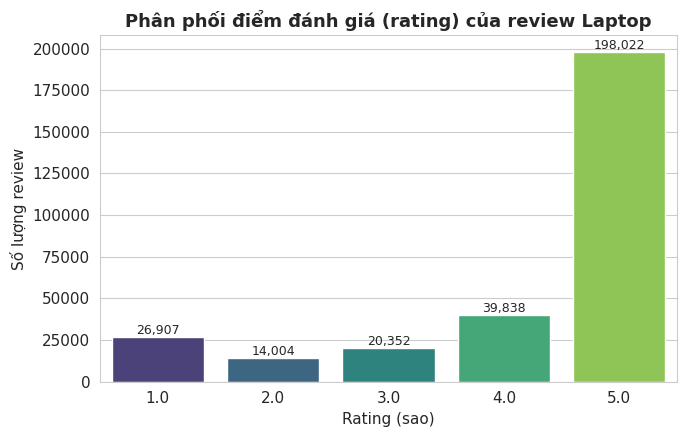

rating
1.0      9.0 %
2.0     4.68 %
3.0      6.8 %
4.0    13.32 %
5.0     66.2 %
Name: proportion, dtype: object


In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
order = sorted(reviews_df_raw["rating"].unique())
sns.countplot(x="rating", data=reviews_df_raw, order=order, palette="viridis", ax=ax)
ax.set_title("Phân phối điểm đánh giá (rating) của review Laptop")
ax.set_xlabel("Rating (sao)")
ax.set_ylabel("Số lượng review")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
save_fig("01_phan_phoi_rating")
plt.show()

print(reviews_df_raw["rating"].value_counts(normalize=True).sort_index().mul(100).round(2).astype(str) + " %")

**Nhận xét:** dữ liệu review thương mại điện tử thường lệch mạnh về phía rating cao (4-5 sao) —
đây là đặc điểm cố hữu của dữ liệu implicit feedback (người mua có xu hướng để lại review khi hài lòng
nhiều hơn). Điều này ảnh hưởng trực tiếp tới cách tính **confidence** trong ALS (`c_ui = 1 + alpha * r_ui`)
ở Bước 7.

### 4.3 Phân phối số tương tác theo User/Item (hiện tượng Long-tail)

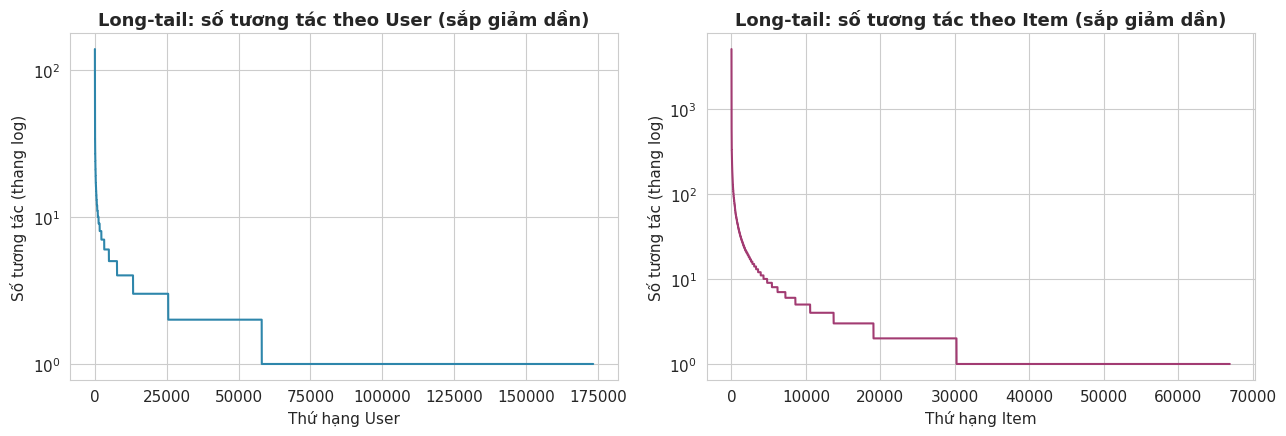

User có nhiều tương tác nhất: 138 review | Trung vị: 1 | Trung bình: 1.73
Item có nhiều tương tác nhất: 5046 review | Trung vị: 1 | Trung bình: 4.47
Tỉ lệ user chỉ có đúng 1 tương tác (cold-start nặng): 66.5%
Tỉ lệ item chỉ có đúng 1 tương tác (cold-start nặng): 54.9%


In [10]:
user_counts_raw = reviews_df_raw["user_id"].value_counts()
item_counts_raw = reviews_df_raw["parent_asin"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(range(1, len(user_counts_raw) + 1), user_counts_raw.values, color="#2E86AB")
axes[0].set_yscale("log")
axes[0].set_title("Long-tail: số tương tác theo User (sắp giảm dần)")
axes[0].set_xlabel("Thứ hạng User")
axes[0].set_ylabel("Số tương tác (thang log)")

axes[1].plot(range(1, len(item_counts_raw) + 1), item_counts_raw.values, color="#A23B72")
axes[1].set_yscale("log")
axes[1].set_title("Long-tail: số tương tác theo Item (sắp giảm dần)")
axes[1].set_xlabel("Thứ hạng Item")
axes[1].set_ylabel("Số tương tác (thang log)")

save_fig("02_long_tail_user_item")
plt.show()

print(f"User có nhiều tương tác nhất: {user_counts_raw.max()} review | Trung vị: {user_counts_raw.median():.0f} | Trung bình: {user_counts_raw.mean():.2f}")
print(f"Item có nhiều tương tác nhất: {item_counts_raw.max()} review | Trung vị: {item_counts_raw.median():.0f} | Trung bình: {item_counts_raw.mean():.2f}")
print(f"Tỉ lệ user chỉ có đúng 1 tương tác (cold-start nặng): {(user_counts_raw == 1).mean()*100:.1f}%")
print(f"Tỉ lệ item chỉ có đúng 1 tương tác (cold-start nặng): {(item_counts_raw == 1).mean()*100:.1f}%")

**Nhận xét:** đường cong giảm rất nhanh (long-tail) là đặc trưng điển hình của dữ liệu tương tác
thương mại điện tử — phần lớn user/item chỉ có 1-2 tương tác, trong khi một số ít user/item "phổ biến"
chiếm phần lớn dữ liệu. Đây chính là **lý do bắt buộc phải lọc nhiễu (Bước 4.5)**: các user/item cold-start
nặng vừa không đủ tín hiệu để mô hình học vừa không thể đánh giá đúng theo protocol leave-one-out
(cần tối thiểu 2 tương tác/user: 1 để train, 1 để test).

### 4.4 Độ thưa (Sparsity) của ma trận User-Item — trước khi lọc

In [11]:
def compute_sparsity(df, user_col="user_id", item_col="parent_asin"):
    '''Độ thưa = tỉ lệ các ô KHÔNG có tương tác trong ma trận User x Item đầy đủ.
    Sparsity càng gần 100% thì bài toán càng khó với Collaborative Filtering thuần túy
    (không đủ tín hiệu đồng-tương-tác để tính similarity giữa user/item) -> đây là luận điểm
    quan trọng để giải thích vì sao Content-Based / Hybrid có ưu thế trên dữ liệu thưa.'''
    n_u = df[user_col].nunique()
    n_i = df[item_col].nunique()
    n_interactions = len(df)
    sparsity = 1 - n_interactions / (n_u * n_i)
    return n_u, n_i, n_interactions, sparsity

n_u, n_i, n_int, sparsity = compute_sparsity(reviews_df_raw)
print(f"[TRƯỚC khi lọc] Số user: {n_u:,} | Số item: {n_i:,} | Số tương tác: {n_int:,}")
print(f"[TRƯỚC khi lọc] Độ thưa ma trận User-Item: {sparsity*100:.4f}%")

[TRƯỚC khi lọc] Số user: 173,365 | Số item: 66,940 | Số tương tác: 299,123
[TRƯỚC khi lọc] Độ thưa ma trận User-Item: 99.9974%


### 4.5 Lọc nhiễu: loại user/item có quá ít tương tác

In [12]:
# Chỉ giữ user có >= MIN_INTERACTIONS tương tác và item có >= MIN_INTERACTIONS tương tác.
# Lý do (đã phân tích ở 4.3): user/item cold-start nặng (1-2 tương tác) vừa gây nhiễu cho quá trình học
# vector latent factor của ALS, vừa không thể tách train/test theo leave-one-out một cách có ý nghĩa.
MIN_INTERACTIONS = 3

reviews_df = reviews_df_raw.copy()
user_counts = reviews_df["user_id"].value_counts()
item_counts = reviews_df["parent_asin"].value_counts()

valid_users = user_counts[user_counts >= MIN_INTERACTIONS].index
valid_items = item_counts[item_counts >= MIN_INTERACTIONS].index

reviews_df = reviews_df[
    reviews_df["user_id"].isin(valid_users) &
    reviews_df["parent_asin"].isin(valid_items)
].reset_index(drop=True)

# Đồng bộ lại metadata: chỉ giữ các item còn xuất hiện trong reviews_df sau khi lọc
meta_df = meta_df[meta_df["parent_asin"].isin(reviews_df["parent_asin"].unique())].reset_index(drop=True)

print(f"Sau khi lọc (MIN_INTERACTIONS={MIN_INTERACTIONS}): {len(reviews_df):,} review | "
      f"{reviews_df['user_id'].nunique():,} user | "
      f"{reviews_df['parent_asin'].nunique():,} item")

Sau khi lọc (MIN_INTERACTIONS=3): 93,250 review | 25,313 user | 17,083 item


### 4.6 So sánh dữ liệu TRƯỚC và SAU khi lọc

,Trước lọc,Sau lọc
Số user,173365,25313
Số item,66940,17083
Số tương tác,299123,93250
Độ thưa ma trận,99.9974%,99.9784%


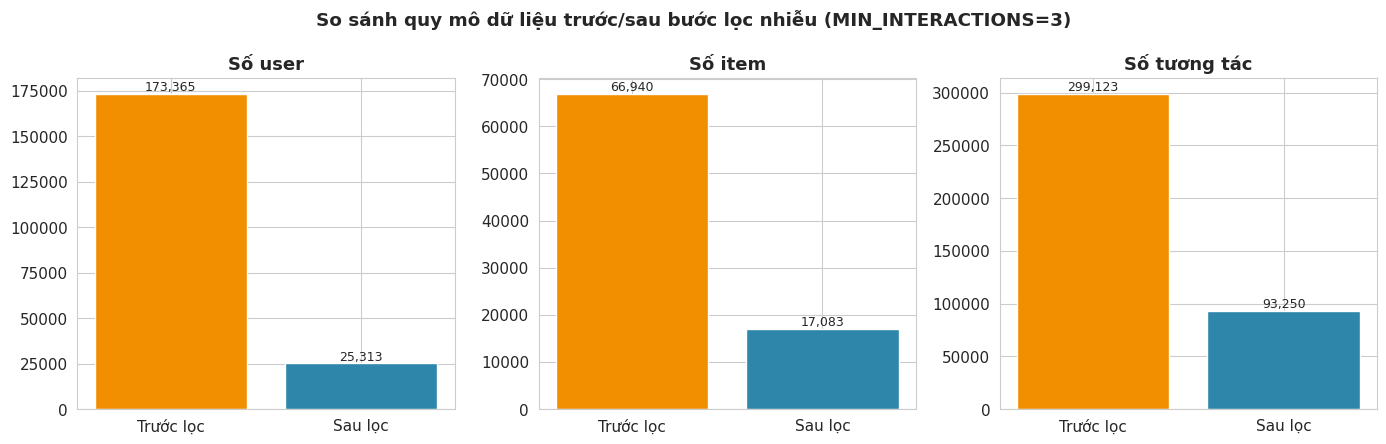


Tỉ lệ user còn giữ lại: 14.6%  |  Tỉ lệ item còn giữ lại: 25.5%  |  Tỉ lệ tương tác còn giữ lại: 31.2%
Lưu ý: độ thưa TĂNG nhẹ sau khi lọc là bình thường — vì ta loại bớt các user/item có rất ít
tương tác (vốn góp phần làm giảm tỉ lệ ô trống một cách 'giả tạo' trong ma trận gốc);
phần dữ liệu còn lại có mật độ tương tác/user và tương tác/item cao hơn, phù hợp để học mô hình hơn.


In [13]:
n_u2, n_i2, n_int2, sparsity2 = compute_sparsity(reviews_df)

compare_df = pd.DataFrame({
    "Trước lọc": [n_u, n_i, n_int, f"{sparsity*100:.4f}%"],
    "Sau lọc":   [n_u2, n_i2, n_int2, f"{sparsity2*100:.4f}%"],
}, index=["Số user", "Số item", "Số tương tác", "Độ thưa ma trận"])
display(compare_df)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
labels = ["Trước lọc", "Sau lọc"]
metrics = [("Số user", [n_u, n_u2]), ("Số item", [n_i, n_i2]), ("Số tương tác", [n_int, n_int2])]
colors = ["#F18F01", "#2E86AB"]
for ax, (title, values) in zip(axes, metrics):
    bars = ax.bar(labels, values, color=colors)
    ax.set_title(title)
    for b in bars:
        ax.annotate(f"{int(b.get_height()):,}", (b.get_x() + b.get_width()/2, b.get_height()),
                    ha="center", va="bottom", fontsize=9)
fig.suptitle("So sánh quy mô dữ liệu trước/sau bước lọc nhiễu (MIN_INTERACTIONS=3)", fontweight="bold")
save_fig("03_truoc_sau_loc_nhieu")
plt.show()

print(f"\nTỉ lệ user còn giữ lại: {n_u2/n_u*100:.1f}%  |  Tỉ lệ item còn giữ lại: {n_i2/n_i*100:.1f}%  "
      f"|  Tỉ lệ tương tác còn giữ lại: {n_int2/n_int*100:.1f}%")
print("Lưu ý: độ thưa TĂNG nhẹ sau khi lọc là bình thường — vì ta loại bớt các user/item có rất ít\n"
      "tương tác (vốn góp phần làm giảm tỉ lệ ô trống một cách 'giả tạo' trong ma trận gốc);\n"
      "phần dữ liệu còn lại có mật độ tương tác/user và tương tác/item cao hơn, phù hợp để học mô hình hơn.")

### 4.7 Phân phối độ dài văn bản mô tả sản phẩm (đầu vào cho Content-Based)

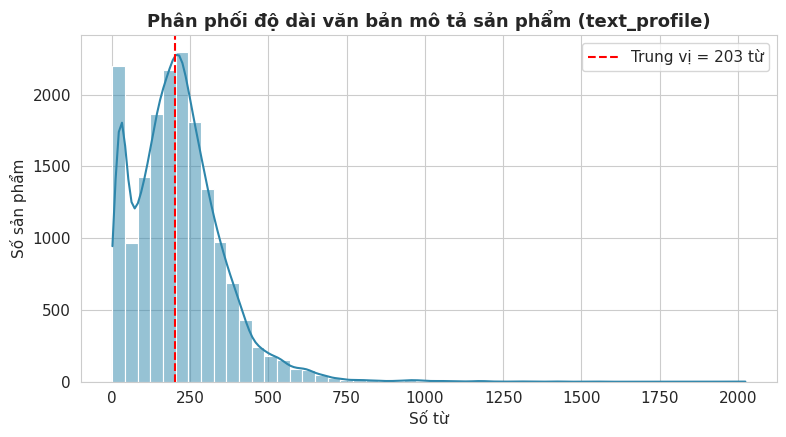

Số sản phẩm có text_profile rỗng (không có title/description/feature nào): 0 (0.00%) -- các sản phẩm này sẽ có vector TF-IDF toàn số 0,
ảnh hưởng tới Content-Based/BERT-ALS cho riêng nhóm item đó (hạn chế cần nêu trong luận văn).


In [14]:
meta_df["text_len_words"] = meta_df["text_profile"].str.split().apply(len)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(meta_df["text_len_words"], bins=50, kde=True, color="#2E86AB", ax=ax)
ax.axvline(meta_df["text_len_words"].median(), color="red", linestyle="--",
           label=f"Trung vị = {meta_df['text_len_words'].median():.0f} từ")
ax.set_title("Phân phối độ dài văn bản mô tả sản phẩm (text_profile)")
ax.set_xlabel("Số từ")
ax.set_ylabel("Số sản phẩm")
ax.legend()
save_fig("04_do_dai_van_ban")
plt.show()

n_empty = (meta_df["text_len_words"] == 0).sum()
print(f"Số sản phẩm có text_profile rỗng (không có title/description/feature nào): {n_empty:,} "
      f"({n_empty/len(meta_df)*100:.2f}%) -- các sản phẩm này sẽ có vector TF-IDF toàn số 0,\n"
      f"ảnh hưởng tới Content-Based/BERT-ALS cho riêng nhóm item đó (hạn chế cần nêu trong luận văn).")

### 4.8 Từ khóa phổ biến trong mô tả sản phẩm (WordCloud)

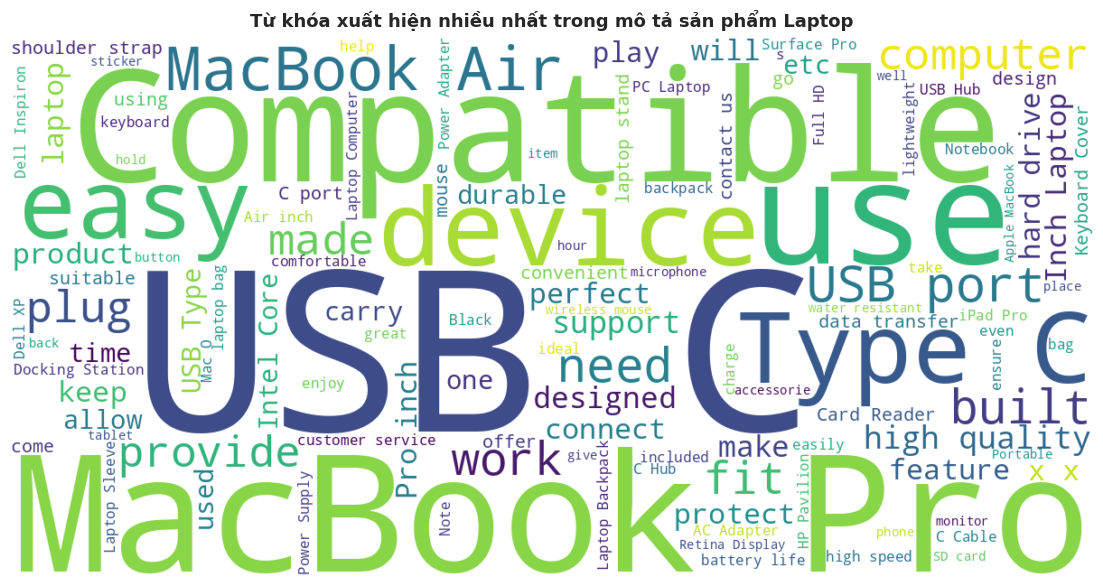

In [15]:
try:
    from wordcloud import WordCloud, STOPWORDS

    text_all = " ".join(meta_df["text_profile"].sample(min(20000, len(meta_df)), random_state=GLOBAL_SEED))
    wc = WordCloud(
        width=1200, height=600, background_color="white",
        stopwords=STOPWORDS, max_words=120, colormap="viridis"
    ).generate(text_all)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Từ khóa xuất hiện nhiều nhất trong mô tả sản phẩm Laptop", fontweight="bold")
    save_fig("05_wordcloud_tu_khoa")
    plt.show()
except ImportError:
    print("Thư viện wordcloud chưa cài được trong môi trường này -> bỏ qua bước trực quan hóa WordCloud "
          "(không ảnh hưởng tới các bước huấn luyện/đánh giá mô hình phía sau).")

### 4.9 Phân phối giá sản phẩm & xử lý giá trị thiếu

Số sản phẩm thiếu thông tin giá (sau khi ép kiểu số): 7,686 / 17,083 (45.0%)


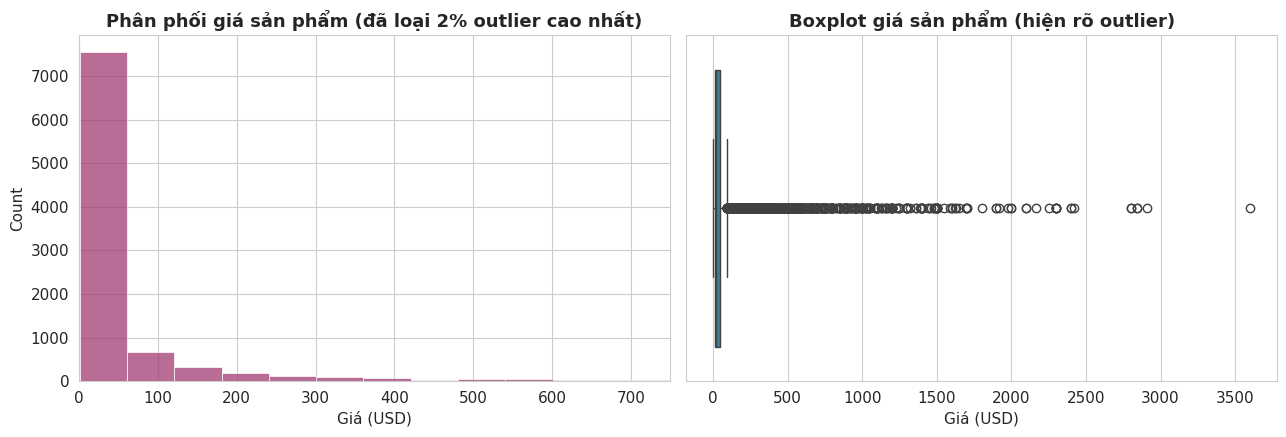

count    9397.00
mean       78.79
std       206.01
min         0.89
25%        13.99
50%        23.95
75%        45.99
max      3599.99
Name: price_numeric, dtype: float64


In [16]:
# Cột "price" trong dữ liệu gốc có kiểu object (chuỗi), có thể chứa giá trị dạng số-dạng-chuỗi,
# chuỗi rỗng, "None", hoặc lẫn ký hiệu như dấu phẩy ngăn cách hàng nghìn -> cần ép kiểu về số (numeric)
# một cách an toàn trước khi so sánh/vẽ biểu đồ, nếu không sẽ lỗi khi so sánh str với int.
price_numeric = (
    meta_df["price"]
    .astype(str)
    .str.replace(r"[^0-9.]", "", regex=True)   # loại bỏ mọi ký tự không phải số/dấu chấm (vd: "$", ",")
    .replace("", np.nan)
)
meta_df["price_numeric"] = pd.to_numeric(price_numeric, errors="coerce")  # chuỗi không hợp lệ -> NaN

price_missing = meta_df["price_numeric"].isnull().sum()
print(f"Số sản phẩm thiếu thông tin giá (sau khi ép kiểu số): {price_missing:,} / {len(meta_df):,} "
      f"({price_missing/len(meta_df)*100:.1f}%)")
# Amazon Reviews 2023 có tỉ lệ thiếu giá khá cao (sản phẩm ngừng bán/không còn niêm yết) -> đây là hạn chế
# của nguồn dữ liệu; ta KHÔNG dùng price làm đặc trưng đầu vào cho mô hình (chỉ dùng để mô tả/EDA),
# nên không cần impute giá trị thiếu, tránh đưa nhiễu giả vào text_profile.

price_valid = meta_df["price_numeric"].dropna()
price_valid = price_valid[price_valid > 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(price_valid, bins=60, color="#A23B72", ax=axes[0])
axes[0].set_xlim(0, price_valid.quantile(0.98))  # cắt bớt outlier cực trị để biểu đồ dễ đọc
axes[0].set_title("Phân phối giá sản phẩm (đã loại 2% outlier cao nhất)")
axes[0].set_xlabel("Giá (USD)")

sns.boxplot(x=price_valid, color="#2E86AB", ax=axes[1])
axes[1].set_title("Boxplot giá sản phẩm (hiện rõ outlier)")
axes[1].set_xlabel("Giá (USD)")

save_fig("06_phan_phoi_gia")
plt.show()

print(price_valid.describe().round(2))

**Tóm tắt EDA & tiền xử lý (Bước 4):** dữ liệu thô có độ lệch mạnh về rating cao, phân phối
tương tác dạng long-tail điển hình và độ thưa rất lớn (>99.9%) — đúng như bản chất bài toán Implicit
Recommendation trong thực tế. Sau khi lọc user/item có dưới 3 tương tác, dữ liệu được giữ lại vẫn đảm
bảo đủ tín hiệu để huấn luyện và đánh giá theo protocol leave-one-out ở Bước 5, đồng thời loại bỏ phần
lớn nhiễu cold-start cực đoan không thể học được với bất kỳ mô hình nào.

## Bước 5: Encode ID & chia Train/Test (Leave-One-Out)

Với mỗi user, tương tác **gần nhất theo thời gian** được giữ lại làm test, phần còn lại làm train
(chuẩn đánh giá phổ biến trong các paper về Implicit Recommendation / NCF — He et al., 2017).

In [17]:
from sklearn.preprocessing import LabelEncoder

# LabelEncoder chuyển user_id/parent_asin (dạng chuỗi) thành chỉ số nguyên liên tục 0..n-1
# -> bắt buộc để xây ma trận thưa (sparse matrix) user-item cho ALS/BPR
user_enc = LabelEncoder()
item_enc = LabelEncoder()

reviews_df["user_idx"] = user_enc.fit_transform(reviews_df["user_id"])
reviews_df["item_idx"] = item_enc.fit_transform(reviews_df["parent_asin"])

n_users = reviews_df["user_idx"].nunique()
n_items = reviews_df["item_idx"].nunique()
print(f"n_users={n_users}, n_items={n_items}")

# Sắp xếp theo thời gian trong từng user để lấy đúng "tương tác gần nhất" làm test
reviews_df = reviews_df.sort_values(["user_idx", "timestamp"])

test_rows = reviews_df.groupby("user_idx").tail(1)     # 1 tương tác gần nhất/user -> test
train_rows = reviews_df.drop(test_rows.index)           # phần còn lại -> train

print(f"Train: {len(train_rows):,} dòng | Test: {len(test_rows):,} dòng (1 dòng / user)")

n_users=25313, n_items=17083
Train: 67,937 dòng | Test: 25,313 dòng (1 dòng / user)


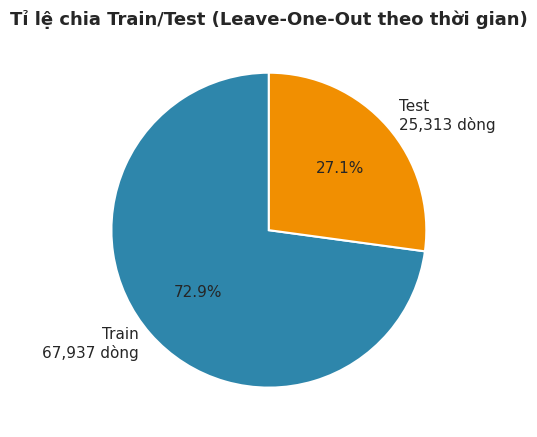

In [18]:
# Trực quan hóa tỉ lệ Train/Test để đưa vào phần "Thiết kế thực nghiệm" của báo cáo
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sizes = [len(train_rows), len(test_rows)]
labels = [f"Train\n{len(train_rows):,} dòng", f"Test\n{len(test_rows):,} dòng"]
ax.pie(sizes, labels=labels, autopct="%1.1f%%", colors=["#2E86AB", "#F18F01"], startangle=90,
       wedgeprops={"edgecolor": "white", "linewidth": 1.5})
ax.set_title("Tỉ lệ chia Train/Test (Leave-One-Out theo thời gian)")
save_fig("07_ty_le_train_test")
plt.show()

## Bước 6: Model 1 — Content-Based Filtering (TF-IDF)

Xây vector TF-IDF từ `title + store + features + description` cho từng item — vector này đóng vai
trò tương đương "BERT embedding" trong hệ thống thật (ở đây dùng TF-IDF vì dữ liệu Amazon là tiếng
Anh; khi áp dụng lại cho sản phẩm laptop tiếng Việt ở Giai đoạn 2, chỉ cần thay bước này bằng
**PhoBERT / Sentence-Transformers tiếng Việt** — kiến trúc pipeline giữ nguyên, chỉ đổi encoder).

User profile = trung bình có trọng số của các vector item mà user đã tương tác trong tập train
(trọng số = rating).

In [19]:
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

# Sắp xếp lại metadata theo đúng thứ tự item_idx để hàng thứ i của item_tfidf tương ứng đúng item_idx=i
item_id_order = item_enc.classes_  # parent_asin theo thứ tự item_idx
meta_indexed = meta_df.set_index("parent_asin").reindex(item_id_order)
meta_indexed["text_profile"] = meta_indexed["text_profile"].fillna("")

tfidf = TfidfVectorizer(max_features=20000, stop_words="english")
item_tfidf = tfidf.fit_transform(meta_indexed["text_profile"])
item_tfidf = normalize(item_tfidf)   # chuẩn hóa L2 -> tích vô hướng giữa 2 vector = cosine similarity
print("TF-IDF item matrix:", item_tfidf.shape)

TF-IDF item matrix: (17083, 20000)


In [20]:
# Ma trận user-item train (dùng rating làm trọng số) để build user profile
train_weight_matrix = sp.csr_matrix(
    (train_rows["rating"].values, (train_rows["user_idx"], train_rows["item_idx"])),
    shape=(n_users, n_items)
)
user_tfidf = train_weight_matrix @ item_tfidf   # (n_users x n_features): trung bình có trọng số các vector item đã tương tác
user_tfidf = normalize(user_tfidf)
print("TF-IDF user profile matrix:", user_tfidf.shape)

TF-IDF user profile matrix: (25313, 20000)


## Bước 7: Model 2 — Collaborative Filtering (ALS, khởi tạo ngẫu nhiên)

Dùng thư viện `implicit` (chuẩn công nghiệp cho Implicit ALS — Hu, Koren, Volinsky 2008).
Confidence: `c_ui = 1 + alpha * r_ui`, với `r_ui` là rating 1-5 của Amazon — user/item càng tương
tác với rating cao thì độ tin cậy tín hiệu implicit càng lớn.

In [21]:
from implicit.als import AlternatingLeastSquares

ALPHA = 15.0     # hệ số khuếch đại confidence, khuyến nghị chuẩn trong khoảng 10-40 (Hu et al., 2008)
FACTORS = 64     # số chiều của latent factor -> dùng chung cho ALS/BERT-ALS/BPR để so sánh công bằng

train_conf = 1 + ALPHA * train_rows["rating"].values
train_matrix = sp.csr_matrix(
    (train_conf, (train_rows["user_idx"], train_rows["item_idx"])),
    shape=(n_users, n_items)
)

als_model = AlternatingLeastSquares(
    factors=FACTORS,
    regularization=0.01,
    iterations=20,
    random_state=GLOBAL_SEED
)
als_model.fit(train_matrix)
print("Đã train xong ALS (random init).")

  0%|          | 0/20 [00:00<?, ?it/s]

Đã train xong ALS (random init).


## Bước 8: Model 3 — BERT-ALS (ALS khởi tạo từ Content Embedding)

Thay vì để `implicit` tự khởi tạo `item_factors` ngẫu nhiên, ta **giảm chiều vector content (TF-IDF,
hoặc PhoBERT ở Giai đoạn 2) xuống đúng số factor bằng TruncatedSVD, rồi gán thẳng làm điểm khởi tạo
cho ALS** trước khi gọi `.fit()`. Thư viện `implicit` (bản ≥0.6) chỉ random-init nếu `item_factors`
đang là `None`, nên gán trước là hợp lệ và được `implicit` tôn trọng.

Lợi ích kỳ vọng: hội tụ nhanh hơn, cold-items được "neo" ngữ nghĩa từ đầu → Recall/NDCG tăng nhẹ.
Đánh đổi: Coverage/Diversity có thể giảm vì các item ngữ nghĩa gần nhau dễ bị gom nhóm — cần đo cả 2
phía để thảo luận trong luận văn.

In [22]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=FACTORS, random_state=GLOBAL_SEED)
item_embed_reduced = svd.fit_transform(item_tfidf)  # (n_items, FACTORS)
explained = svd.explained_variance_ratio_.sum()
print(f"TruncatedSVD giữ lại {explained*100:.1f}% variance với {FACTORS} chiều")

item_embed_reduced = normalize(item_embed_reduced).astype(np.float32)

bert_als_model = AlternatingLeastSquares(
    factors=FACTORS,
    regularization=0.1,   # tăng regularization để giữ ổn định điểm khởi tạo
    iterations=15,
    random_state=GLOBAL_SEED
)
bert_als_model.item_factors = item_embed_reduced.copy()  # gán trước -> implicit dùng làm điểm khởi tạo thay vì random
bert_als_model.fit(train_matrix)
print("Đã train xong BERT-ALS (content-init).")

TruncatedSVD giữ lại 27.8% variance với 64 chiều


  0%|          | 0/15 [00:00<?, ?it/s]

Đã train xong BERT-ALS (content-init).


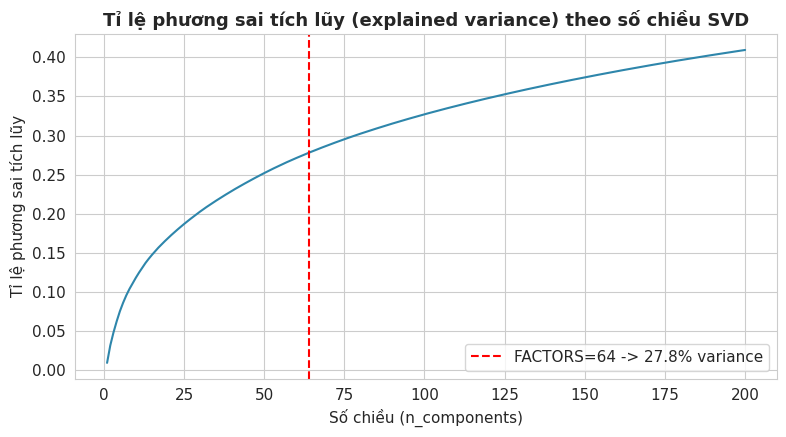

In [23]:
# Trực quan hóa % variance được giữ lại theo từng số chiều -> minh chứng cho việc chọn FACTORS=64
svd_full_check = TruncatedSVD(n_components=min(200, item_tfidf.shape[1]-1), random_state=GLOBAL_SEED)
svd_full_check.fit(item_tfidf)
cum_var = np.cumsum(svd_full_check.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(cum_var)+1), cum_var, color="#2E86AB")
ax.axvline(FACTORS, color="red", linestyle="--", label=f"FACTORS={FACTORS} -> {cum_var[FACTORS-1]*100:.1f}% variance")
ax.set_title("Tỉ lệ phương sai tích lũy (explained variance) theo số chiều SVD")
ax.set_xlabel("Số chiều (n_components)")
ax.set_ylabel("Tỉ lệ phương sai tích lũy")
ax.legend()
save_fig("08_svd_explained_variance")
plt.show()

## Bước 9: Model 4 — BPR (Bayesian Personalized Ranking)

BPR tối ưu **thứ hạng tương đối** giữa item đã tương tác và item chưa tương tác, thay vì dự đoán giá
trị confidence tuyệt đối như ALS — phù hợp làm baseline đối trọng để so sánh trong luận văn.

In [24]:
from implicit.bpr import BayesianPersonalizedRanking

bpr_model = BayesianPersonalizedRanking(
    factors=FACTORS,
    learning_rate=0.05,
    regularization=0.01,
    iterations=80,
    random_state=GLOBAL_SEED
)
bpr_model.fit(train_matrix)
print("Đã train xong BPR.")

  0%|          | 0/80 [00:00<?, ?it/s]

Đã train xong BPR.


## Bước 10: Hàm đánh giá — HitRate@K, NDCG@10, Coverage, Diversity

Theo protocol chuẩn (He et al., NCF 2017): với mỗi user trong tập test, lấy 1 item positive (giữ lại
ở bước leave-one-out) + 99 item negative (chưa từng tương tác), xếp hạng 100 item này theo điểm số
của từng model.

Thêm 2 chỉ số **Coverage** và **Diversity** để có cơ sở thảo luận trade-off Accuracy vs Diversity
trong luận văn — không chỉ dừng ở Recall/NDCG:
- **Coverage** = tỉ lệ item khác nhau từng được xếp Top-10 cho ít nhất 1 user / tổng số item.
- **Diversity** = 1 − trung bình cosine similarity (theo TF-IDF) giữa các cặp item trong Top-10 của
  mỗi user, trung bình trên toàn bộ user test.

Hàm `evaluate_model_seeded` (nhận seed tùy ý) được định nghĩa ngay tại đây để tái sử dụng cho cả
**tìm trọng số Hybrid tối ưu (Bước 11)** lẫn **kiểm tra độ ổn định đa seed (Bước 14)**.

In [25]:
import random

user_train_items = train_rows.groupby("user_idx")["item_idx"].apply(set).to_dict()

N_NEG = 99            # số item negative lấy mẫu / user, theo chuẩn NCF (1 positive + 99 negative)
K_LIST = [5, 10, 20]  # các ngưỡng Top-K để tính HitRate/Recall@K

def sample_negatives(rnd_obj, user_idx, positive_item, n_neg=N_NEG):
    '''Lấy mẫu ngẫu nhiên n_neg item mà user CHƯA từng tương tác (cả train lẫn positive test).'''
    interacted = user_train_items.get(user_idx, set()) | {positive_item}
    negs = []
    while len(negs) < n_neg:
        cand = rnd_obj.randrange(n_items)
        if cand not in interacted:
            negs.append(cand)
    return negs

def evaluate_model_seeded(score_fn, seed, k_list=K_LIST, with_diversity=False):
    '''Đánh giá 1 model (score_fn: (user_idx, candidate_idx_array) -> score_array) với 1 seed lấy mẫu
    negative cụ thể. Trả về (recall_at_k: dict, ndcg@10: float[, coverage, diversity nếu with_diversity=True]).
    Tách seed ra tham số riêng (thay vì cố định random.seed toàn cục) để có thể gọi lặp lại với nhiều
    seed khác nhau nhằm đo phương sai (Bước 14) mà không ảnh hưởng lẫn nhau giữa các lần gọi.'''
    rnd = random.Random(seed)
    hits_at_k = {k: [] for k in k_list}
    ndcgs = []
    top10_per_user = {} if with_diversity else None

    for _, row in test_rows.iterrows():
        u, pos = int(row["user_idx"]), int(row["item_idx"])
        negs = sample_negatives(rnd, u, pos)
        candidates = np.array([pos] + negs)
        scores = score_fn(u, candidates)
        ranked = candidates[np.argsort(-scores)]
        rank_of_pos = int(np.where(ranked == pos)[0][0]) + 1  # 1-indexed

        for k in k_list:
            hits_at_k[k].append(1 if rank_of_pos <= k else 0)
        ndcgs.append(1 / np.log2(rank_of_pos + 1) if rank_of_pos <= 10 else 0.0)
        if with_diversity:
            top10_per_user[u] = ranked[:10]

    recall_at_k = {k: float(np.mean(hits_at_k[k])) for k in k_list}
    ndcg10 = float(np.mean(ndcgs))

    if not with_diversity:
        return recall_at_k, ndcg10

    all_recommended = set()
    for items in top10_per_user.values():
        all_recommended.update(items.tolist())
    coverage = len(all_recommended) / n_items

    div_scores = []
    for items in top10_per_user.values():
        if len(items) < 2:
            continue
        vecs = item_tfidf[items]
        sim_matrix = (vecs @ vecs.T).toarray()
        iu = np.triu_indices(len(items), k=1)
        avg_sim = sim_matrix[iu].mean() if len(iu[0]) > 0 else 0.0
        div_scores.append(1 - avg_sim)
    diversity = float(np.mean(div_scores)) if div_scores else 0.0

    return recall_at_k, ndcg10, coverage, diversity

def evaluate_model(score_fn, k_list=K_LIST, seed=GLOBAL_SEED):
    '''Bản đánh giá đầy đủ (kèm Coverage/Diversity) dùng seed mặc định GLOBAL_SEED -- dùng cho bảng
    so sánh chính thức ở Bước 12.'''
    return evaluate_model_seeded(score_fn, seed=seed, k_list=k_list, with_diversity=True)

# Các hàm tính điểm (score function) cho từng model — dùng chung interface (user_idx, candidate_idx) -> score
def minmax_norm(scores):
    '''Chuẩn hóa Min-Max về [0,1] -- bắt buộc trước khi cộng có trọng số 2 loại điểm số có thang đo
    khác nhau (cosine similarity của Content-Based nằm trong [0,1] còn tích vô hướng latent factor
    của ALS có thể âm/dương không giới hạn).'''
    lo, hi = scores.min(), scores.max()
    if hi - lo < 1e-9:
        return np.zeros_like(scores)
    return (scores - lo) / (hi - lo)

def score_content(user_idx, candidate_idx):
    sims = (user_tfidf[user_idx] @ item_tfidf[candidate_idx].T).toarray().ravel()
    return sims

def score_als(user_idx, candidate_idx):
    user_vec = als_model.user_factors[user_idx]
    item_vecs = als_model.item_factors[candidate_idx]
    return item_vecs @ user_vec

def score_bert_als(user_idx, candidate_idx):
    user_vec = bert_als_model.user_factors[user_idx]
    item_vecs = bert_als_model.item_factors[candidate_idx]
    return item_vecs @ user_vec

def score_bpr(user_idx, candidate_idx):
    user_vec = bpr_model.user_factors[user_idx]
    item_vecs = bpr_model.item_factors[candidate_idx]
    return item_vecs @ user_vec

print("Đã định nghĩa xong bộ hàm đánh giá và các hàm tính điểm cho 4 model cơ sở.")

Đã định nghĩa xong bộ hàm đánh giá và các hàm tính điểm cho 4 model cơ sở.


## Bước 11: Model 5 — Hybrid: tìm kiếm trọng số tối ưu

Hệ thống thật (`recommendationService.js`) đang dùng trọng số cố định **Content 0.7 / ALS 0.3**.
Ở bước này ta **grid search** trọng số `content_weight` từ 0.0 đến 1.0 (bước nhảy 0.05, tổng 21 điểm,
với `als_weight = 1 - content_weight`), đánh giá mỗi điểm bằng **trung bình NDCG@10 và Recall@10 trên
nhiều seed** (giảm nhiễu do lấy mẫu negative ngẫu nhiên — xem thêm Bước 14 về độ ổn định), rồi chọn
cấu hình có **NDCG@10 trung bình cao nhất** làm trọng số Hybrid tối ưu cho báo cáo.

Công thức: `score_hybrid = content_weight * minmax(score_content) + als_weight * minmax(score_als)`

In [26]:
def hybrid_score_fn(cw, aw):
    '''Trả về 1 hàm score(user_idx, candidate_idx) ứng với cặp trọng số (cw, aw) cụ thể.
    Đóng gói thành closure để dùng trực tiếp với evaluate_model_seeded.'''
    def _score(user_idx, candidate_idx):
        c = minmax_norm(score_content(user_idx, candidate_idx))
        a = minmax_norm(score_als(user_idx, candidate_idx))
        return cw * c + aw * a
    return _score

def evaluate_hybrid_weight(cw, aw, seeds):
    '''Đánh giá 1 cặp trọng số trên nhiều seed, trả về (R@10 trung bình, NDCG@10 trung bình, std NDCG@10).'''
    fn = hybrid_score_fn(cw, aw)
    r10s, ndcgs = [], []
    for s in seeds:
        r, n = evaluate_model_seeded(fn, seed=s)
        r10s.append(r[10]); ndcgs.append(n)
    return float(np.mean(r10s)), float(np.mean(ndcgs)), float(np.std(ndcgs))

# Grid trọng số: 0.00, 0.05, 0.10, ..., 1.00 (bước 0.05 -> chi tiết hơn nhiều so với thử thủ công 0.1)
WEIGHT_GRID = np.round(np.arange(0.0, 1.0001, 0.05), 2)
TUNE_SEEDS = [42, 7, 123]   # trung bình trên 3 seed để kết quả tin cậy hơn 1 lần chạy đơn lẻ

print(f"Đang grid search {len(WEIGHT_GRID)} cấu hình trọng số Hybrid "
      f"(mỗi cấu hình đánh giá trên {len(TUNE_SEEDS)} seed)...")

weight_search_rows = []
for cw in WEIGHT_GRID:
    aw = round(1.0 - cw, 2)
    r10_mean, ndcg_mean, ndcg_std = evaluate_hybrid_weight(cw, aw, TUNE_SEEDS)
    weight_search_rows.append({
        "content_weight": cw, "als_weight": aw,
        "R@10 (mean)": r10_mean, "NDCG@10 (mean)": ndcg_mean, "NDCG@10 (std)": ndcg_std,
    })

weight_search_df = pd.DataFrame(weight_search_rows)
weight_search_df

Đang grid search 21 cấu hình trọng số Hybrid (mỗi cấu hình đánh giá trên 3 seed)...


,content_weight,als_weight,R@10 (mean),NDCG@10 (mean),NDCG@10 (std)
0,0.00,1.00,0.310828,0.213342,0.000179
1,0.05,0.95,0.318163,0.217092,0.000385
2,0.10,0.90,0.326341,0.221661,0.000506
3,0.15,0.85,0.336428,0.227080,0.000149
4,0.20,0.80,0.347410,0.232911,0.000314
5,0.25,0.75,0.357840,0.238788,0.000204
6,0.30,0.70,0.365530,0.243625,0.000172
7,0.35,0.65,0.369296,0.246277,0.000107
8,0.40,0.60,0.372444,0.247052,0.000153
9,0.45,0.55,0.371798,0.244892,0.000263


In [27]:
# Chọn trọng số tối ưu: ưu tiên NDCG@10 trung bình cao nhất, nếu hòa thì chọn R@10 cao hơn
best_row = weight_search_df.sort_values(["NDCG@10 (mean)", "R@10 (mean)"], ascending=False).iloc[0]
BEST_CONTENT_WEIGHT = float(best_row["content_weight"])
BEST_ALS_WEIGHT = float(best_row["als_weight"])

print(f"==> Trọng số Hybrid TỐI ƯU tìm được: content_weight={BEST_CONTENT_WEIGHT}, "
      f"als_weight={BEST_ALS_WEIGHT}")
print(f"    NDCG@10 trung bình = {best_row['NDCG@10 (mean)']:.4f} "
      f"(so với cấu hình gốc 0.7/0.3 hệ thống đang dùng)")

# Trọng số hệ thống gốc (0.7/0.3) để đối chiếu trực tiếp trong bảng và biểu đồ
baseline_row = weight_search_df.loc[weight_search_df["content_weight"] == 0.7].iloc[0]
print(f"    Đối chiếu — cấu hình gốc 0.7/0.3: NDCG@10 trung bình = {baseline_row['NDCG@10 (mean)']:.4f}")

==> Trọng số Hybrid TỐI ƯU tìm được: content_weight=0.4, als_weight=0.6
    NDCG@10 trung bình = 0.2471 (so với cấu hình gốc 0.7/0.3 hệ thống đang dùng)
    Đối chiếu — cấu hình gốc 0.7/0.3: NDCG@10 trung bình = 0.2207


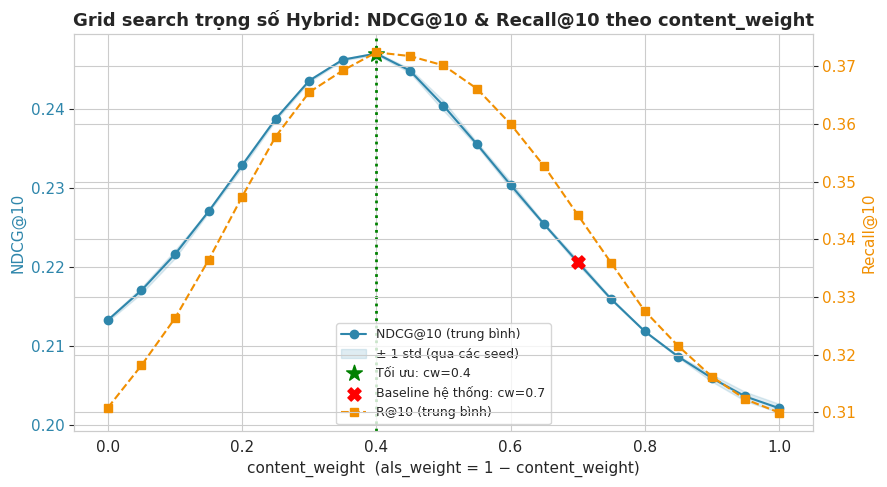

In [28]:
# Trực quan hóa đường cong NDCG@10 / R@10 theo trọng số content_weight -> biểu đồ then chốt cho
# phần "Lựa chọn trọng số Hybrid" trong luận văn/slide bảo vệ
fig, ax1 = plt.subplots(figsize=(9, 5))

ax1.plot(weight_search_df["content_weight"], weight_search_df["NDCG@10 (mean)"],
         marker="o", color="#2E86AB", label="NDCG@10 (trung bình)")
ax1.fill_between(
    weight_search_df["content_weight"],
    weight_search_df["NDCG@10 (mean)"] - weight_search_df["NDCG@10 (std)"],
    weight_search_df["NDCG@10 (mean)"] + weight_search_df["NDCG@10 (std)"],
    color="#2E86AB", alpha=0.15, label="± 1 std (qua các seed)"
)
ax1.set_xlabel("content_weight  (als_weight = 1 − content_weight)")
ax1.set_ylabel("NDCG@10", color="#2E86AB")
ax1.tick_params(axis="y", labelcolor="#2E86AB")

ax2 = ax1.twinx()
ax2.plot(weight_search_df["content_weight"], weight_search_df["R@10 (mean)"],
         marker="s", color="#F18F01", linestyle="--", label="R@10 (trung bình)")
ax2.set_ylabel("Recall@10", color="#F18F01")
ax2.tick_params(axis="y", labelcolor="#F18F01")

# Đánh dấu điểm tối ưu tìm được và điểm baseline 0.7/0.3 để so sánh trực quan
ax1.axvline(BEST_CONTENT_WEIGHT, color="green", linestyle=":", linewidth=2)
ax1.scatter([BEST_CONTENT_WEIGHT], [best_row["NDCG@10 (mean)"]], color="green", s=140, zorder=5,
            marker="*", label=f"Tối ưu: cw={BEST_CONTENT_WEIGHT}")
ax1.scatter([0.7], [baseline_row["NDCG@10 (mean)"]], color="red", s=90, zorder=5,
            marker="X", label="Baseline hệ thống: cw=0.7")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower center", fontsize=9)

ax1.set_title("Grid search trọng số Hybrid: NDCG@10 & Recall@10 theo content_weight")
save_fig("09_hybrid_weight_search")
plt.show()

In [29]:
# Dùng CHÍNH THỨC trọng số tối ưu tìm được cho model Hybrid trong toàn bộ phần đánh giá còn lại.
CONTENT_WEIGHT = BEST_CONTENT_WEIGHT
CF_WEIGHT = BEST_ALS_WEIGHT

score_hybrid = hybrid_score_fn(CONTENT_WEIGHT, CF_WEIGHT)                 # Hybrid với trọng số TỐI ƯU
score_hybrid_baseline = hybrid_score_fn(0.7, 0.3)                          # Hybrid với trọng số GỐC (0.7/0.3) để đối chiếu

print(f"Model Hybrid chính thức sử dụng trọng số: content={CONTENT_WEIGHT} / als={CF_WEIGHT}")

Model Hybrid chính thức sử dụng trọng số: content=0.4 / als=0.6


## Bước 12: Đánh giá tổng hợp toàn bộ mô hình

Đánh giá đầy đủ (HitRate@5/10/20, NDCG@10, Coverage, Diversity) cho **6 cấu hình**: 4 model cơ sở
(Content-Based, ALS, BERT-ALS, BPR) + Hybrid baseline (0.7/0.3, đúng hệ thống thật) + Hybrid tối ưu
(trọng số tìm được ở Bước 11) — để thấy rõ mức cải thiện của việc tinh chỉnh trọng số.

In [30]:
model_scorers = {
    "Content-Based": score_content,
    "ALS (random init)": score_als,
    "BERT-ALS (content init)": score_bert_als,
    "BPR": score_bpr,
    "Hybrid (baseline 0.7/0.3)": score_hybrid_baseline,
    f"Hybrid (tối ưu {CONTENT_WEIGHT}/{CF_WEIGHT})": score_hybrid,
}

rows_report = []
for name, fn in model_scorers.items():
    print(f"Đang đánh giá {name}...")
    recall_at_k, ndcg10, coverage, diversity = evaluate_model(fn)
    rows_report.append({
        "Model": name,
        "R@5": recall_at_k[5],
        "R@10": recall_at_k[10],
        "R@20": recall_at_k[20],
        "NDCG@10": ndcg10,
        "Coverage": coverage,
        "Diversity": diversity,
    })

report = pd.DataFrame(rows_report).sort_values("NDCG@10", ascending=False).reset_index(drop=True)
report

Đang đánh giá Content-Based...
Đang đánh giá ALS (random init)...
Đang đánh giá BERT-ALS (content init)...
Đang đánh giá BPR...
Đang đánh giá Hybrid (baseline 0.7/0.3)...
Đang đánh giá Hybrid (tối ưu 0.4/0.6)...


,Model,R@5,R@10,R@20,NDCG@10,Coverage,Diversity
0,Hybrid (tối ưu 0.4/0.6),0.282780,0.372733,0.483625,0.247269,0.980448,0.912963
1,BERT-ALS (content init),0.261763,0.332359,0.421760,0.230869,0.903413,0.956435
2,Hybrid (baseline 0.7/0.3),0.247146,0.344329,0.482163,0.220436,0.982439,0.878686
3,ALS (random init),0.243353,0.310947,0.397701,0.212942,0.902183,0.957470
4,Content-Based,0.224667,0.309999,0.440564,0.202045,0.983200,0.871325
5,BPR,0.062260,0.100739,0.168649,0.053358,0.815021,0.962988


In [31]:
# Mức cải thiện của Hybrid tối ưu so với Hybrid baseline (0.7/0.3) -- con số then chốt để trả lời
# câu hỏi "tìm trọng số Hybrid có độ chính xác cao hơn" trong phần bảo vệ khóa luận
base_ndcg = report.loc[report["Model"] == "Hybrid (baseline 0.7/0.3)", "NDCG@10"].values[0]
opt_name = f"Hybrid (tối ưu {CONTENT_WEIGHT}/{CF_WEIGHT})"
opt_ndcg = report.loc[report["Model"] == opt_name, "NDCG@10"].values[0]
improve_pct = (opt_ndcg - base_ndcg) / base_ndcg * 100

print(f"NDCG@10 — Hybrid baseline (0.7/0.3): {base_ndcg:.4f}")
print(f"NDCG@10 — Hybrid tối ưu ({CONTENT_WEIGHT}/{CF_WEIGHT}): {opt_ndcg:.4f}")
print(f"Mức cải thiện: {improve_pct:+.2f}%")

NDCG@10 — Hybrid baseline (0.7/0.3): 0.2204
NDCG@10 — Hybrid tối ưu (0.4/0.6): 0.2473
Mức cải thiện: +12.17%


## Bước 13: Trực quan hóa kết quả đánh giá

Bộ biểu đồ dùng trực tiếp cho slide báo cáo/bảo vệ khóa luận: so sánh Recall@K, NDCG@10, và trade-off
Accuracy (NDCG@10) vs Diversity giữa các mô hình.

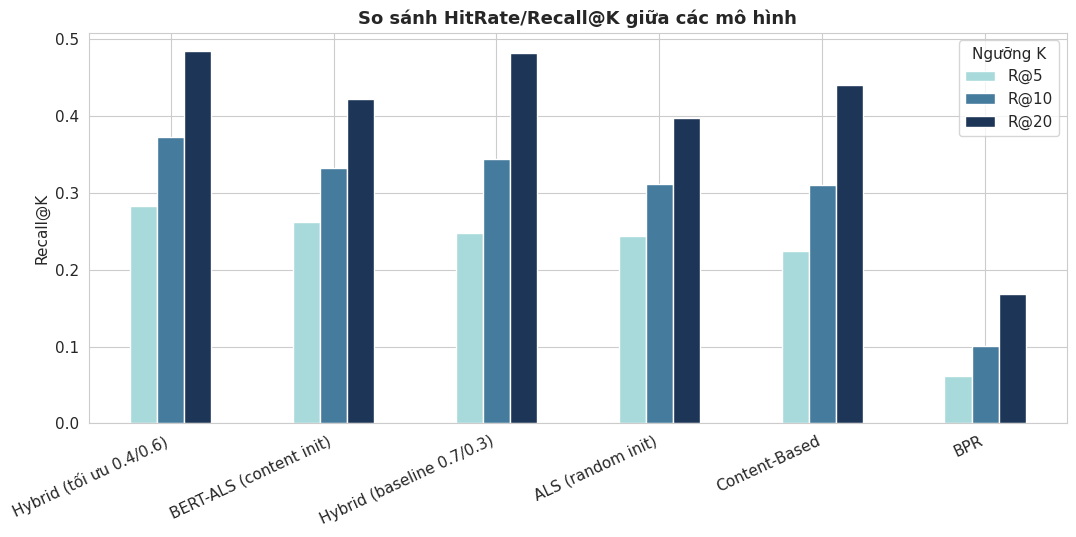

In [32]:
# 13.1 Biểu đồ cột nhóm: Recall@5 / @10 / @20 giữa các model
report_plot = report.set_index("Model")
fig, ax = plt.subplots(figsize=(11, 5.5))
report_plot[["R@5", "R@10", "R@20"]].plot(kind="bar", ax=ax, color=["#A8DADC", "#457B9D", "#1D3557"])
ax.set_title("So sánh HitRate/Recall@K giữa các mô hình")
ax.set_ylabel("Recall@K")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
ax.legend(title="Ngưỡng K")
save_fig("10_so_sanh_recall_at_k")
plt.show()

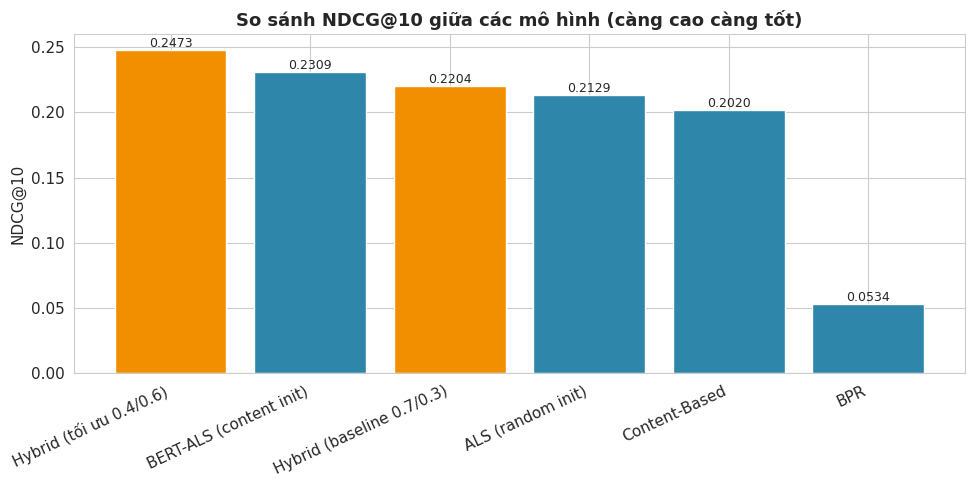

In [33]:
# 13.2 Biểu đồ cột: NDCG@10 -- chỉ số tổng hợp quan trọng nhất để xếp hạng mô hình
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#2E86AB" if "Hybrid" not in m else "#F18F01" for m in report["Model"]]
bars = ax.bar(report["Model"], report["NDCG@10"], color=colors)
ax.set_title("So sánh NDCG@10 giữa các mô hình (càng cao càng tốt)")
ax.set_ylabel("NDCG@10")
plt.xticks(rotation=25, ha="right")
for b in bars:
    ax.annotate(f"{b.get_height():.4f}", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=9)
save_fig("11_so_sanh_ndcg10")
plt.show()

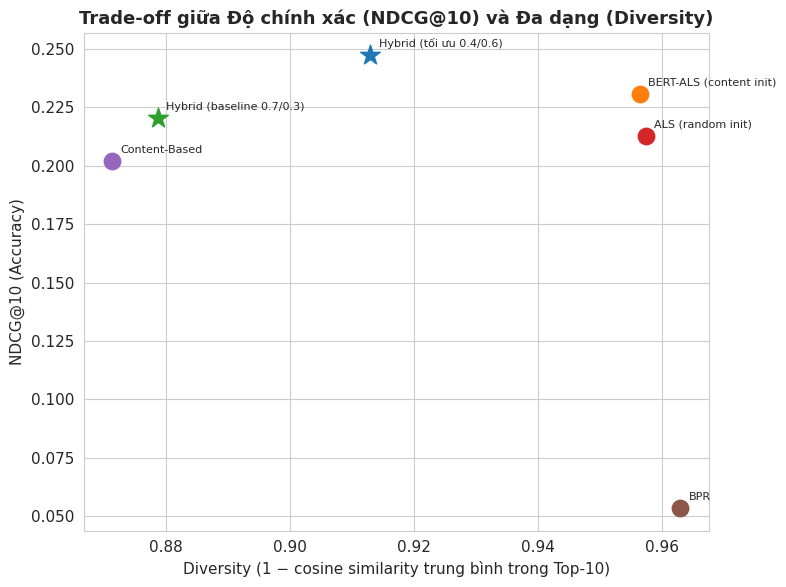

In [34]:
# 13.3 Trade-off Accuracy (NDCG@10) vs Diversity -- luận điểm học thuật về đánh đổi giữa
# độ chính xác và tính đa dạng/khám phá sản phẩm mới, mỗi model là 1 điểm trên biểu đồ
fig, ax = plt.subplots(figsize=(8, 6))
for _, r in report.iterrows():
    marker = "*" if "Hybrid" in r["Model"] else "o"
    size = 220 if "Hybrid" in r["Model"] else 140
    ax.scatter(r["Diversity"], r["NDCG@10"], s=size, marker=marker, label=r["Model"])
    ax.annotate(r["Model"], (r["Diversity"], r["NDCG@10"]),
                textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Diversity (1 − cosine similarity trung bình trong Top-10)")
ax.set_ylabel("NDCG@10 (Accuracy)")
ax.set_title("Trade-off giữa Độ chính xác (NDCG@10) và Đa dạng (Diversity)")
save_fig("12_tradeoff_accuracy_diversity")
plt.show()

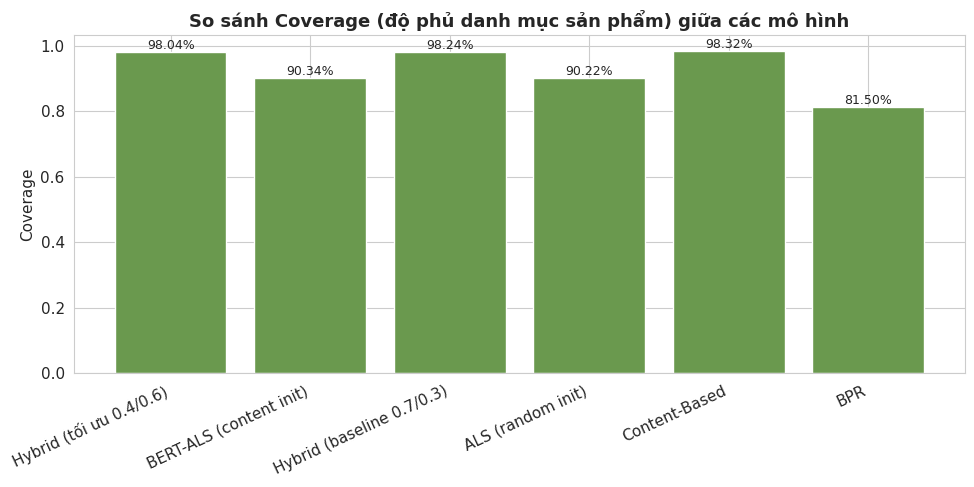

In [35]:
# 13.4 Biểu đồ cột: Coverage -- tỉ lệ danh mục sản phẩm được hệ thống "chạm tới" khi gợi ý
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(report["Model"], report["Coverage"], color="#6A994E")
ax.set_title("So sánh Coverage (độ phủ danh mục sản phẩm) giữa các mô hình")
ax.set_ylabel("Coverage")
plt.xticks(rotation=25, ha="right")
for b in bars:
    ax.annotate(f"{b.get_height():.2%}", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=9)
save_fig("13_so_sanh_coverage")
plt.show()

## Bước 14: Kiểm tra độ ổn định (đa seed)

Bảng kết quả ở Bước 12 chỉ chạy **1 lần** với 1 cách lấy negative ngẫu nhiên (seed cố định) — cần biết
con số đó dao động bao nhiêu nếu đổi seed trước khi kết luận model nào thực sự tốt hơn. Đánh giá lại
mỗi model với **5 seed khác nhau** và trực quan hóa bằng error bar (mean ± std).

In [36]:
SEEDS = [42, 123, 7, 2024, 99]
stability_rows = []
for name, fn in model_scorers.items():
    r10s, ndcgs = [], []
    for s in SEEDS:
        r, n = evaluate_model_seeded(fn, seed=s)
        r10s.append(r[10]); ndcgs.append(n)
    stability_rows.append({
        "Model": name,
        "R@10 (mean)": np.mean(r10s), "R@10 (std)": np.std(r10s),
        "NDCG@10 (mean)": np.mean(ndcgs), "NDCG@10 (std)": np.std(ndcgs),
    })
stability_report = pd.DataFrame(stability_rows).sort_values("NDCG@10 (mean)", ascending=False).reset_index(drop=True)
stability_report

,Model,R@10 (mean),R@10 (std),NDCG@10 (mean),NDCG@10 (std)
0,Hybrid (tối ưu 0.4/0.6),0.372236,0.000572,0.247093,0.000165
1,BERT-ALS (content init),0.333054,0.000551,0.231401,0.000387
2,Hybrid (baseline 0.7/0.3),0.344092,0.001180,0.220541,0.000348
3,ALS (random init),0.310528,0.000893,0.213202,0.000321
4,Content-Based,0.309825,0.000813,0.201872,0.000595
5,BPR,0.101284,0.000464,0.053276,0.000203


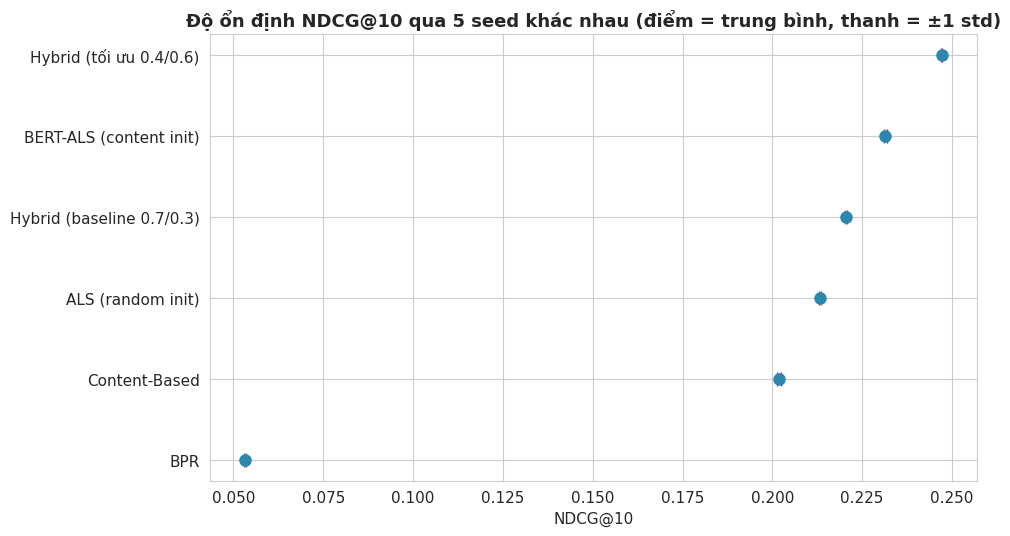

Quy tắc đọc: nếu std > khoảng cách NDCG@10 giữa 2 model liền kề trong bảng Bước 12, thì KHÔNG
nên kết luận model này 'tốt hơn' model kia một cách chắc chắn -- chênh lệch đó có thể nằm trong nhiễu.


In [37]:
# Trực quan hóa độ ổn định bằng error bar (mean ± std qua 5 seed) cho NDCG@10
fig, ax = plt.subplots(figsize=(10, 5.5))
order = stability_report.sort_values("NDCG@10 (mean)")
ax.errorbar(order["NDCG@10 (mean)"], order["Model"], xerr=order["NDCG@10 (std)"],
            fmt="o", color="#2E86AB", ecolor="#A23B72", elinewidth=2, capsize=5, markersize=8)
ax.set_title("Độ ổn định NDCG@10 qua 5 seed khác nhau (điểm = trung bình, thanh = ±1 std)")
ax.set_xlabel("NDCG@10")
save_fig("14_do_on_dinh_ndcg10")
plt.show()

print("Quy tắc đọc: nếu std > khoảng cách NDCG@10 giữa 2 model liền kề trong bảng Bước 12, thì KHÔNG\n"
      "nên kết luận model này 'tốt hơn' model kia một cách chắc chắn -- chênh lệch đó có thể nằm trong nhiễu.")

## Bước 15: Lưu kết quả & xuất hình ảnh phục vụ báo cáo

In [38]:
# Lưu toàn bộ bảng kết quả ra CSV để đưa trực tiếp vào Word/LaTeX của khóa luận
report.to_csv("model_comparison_results.csv", index=False)
stability_report.to_csv("model_stability_results.csv", index=False)
weight_search_df.to_csv("hybrid_weight_search_results.csv", index=False)

print("Đã lưu 3 file CSV kết quả:")
print("  - model_comparison_results.csv      : bảng so sánh chính (Bước 12)")
print("  - model_stability_results.csv       : bảng kiểm tra độ ổn định (Bước 14)")
print("  - hybrid_weight_search_results.csv  : toàn bộ grid search trọng số Hybrid (Bước 11)")
print(f"\nToàn bộ hình ảnh ({len(os.listdir(FIGURE_DIR))} file) đã được lưu trong thư mục: {FIGURE_DIR}/")
print("\n=== BẢNG KẾT QUẢ CHÍNH (Markdown, dán trực tiếp vào báo cáo) ===")
print(report.to_markdown(index=False))

Đã lưu 3 file CSV kết quả:
  - model_comparison_results.csv      : bảng so sánh chính (Bước 12)
  - model_stability_results.csv       : bảng kiểm tra độ ổn định (Bước 14)
  - hybrid_weight_search_results.csv  : toàn bộ grid search trọng số Hybrid (Bước 11)

Toàn bộ hình ảnh (14 file) đã được lưu trong thư mục: figures/

=== BẢNG KẾT QUẢ CHÍNH (Markdown, dán trực tiếp vào báo cáo) ===
| Model                     |       R@5 |     R@10 |     R@20 |   NDCG@10 |   Coverage |   Diversity |
|:--------------------------|----------:|---------:|---------:|----------:|-----------:|------------:|
| Hybrid (tối ưu 0.4/0.6)   | 0.28278   | 0.372733 | 0.483625 |  0.247269 |   0.980448 |    0.912963 |
| BERT-ALS (content init)   | 0.261763  | 0.332359 | 0.42176  |  0.230869 |   0.903413 |    0.956435 |
| Hybrid (baseline 0.7/0.3) | 0.247146  | 0.344329 | 0.482163 |  0.220436 |   0.982439 |    0.878686 |
| ALS (random init)         | 0.243353  | 0.310947 | 0.397701 |  0.212942 |   0.902183 |    0.9574

## Bước 16: Kết luận & định hướng Giai đoạn 2

**Tóm tắt quy trình đã thực hiện:**
1. Tải và tiền xử lý dữ liệu Amazon Reviews 2023 (Electronics/Laptop) — bao gồm làm sạch, lọc nhiễu
   cold-start, và trực quan hóa toàn diện đặc điểm dữ liệu (Bước 4).
2. Huấn luyện 4 mô hình cơ sở: Content-Based (TF-IDF), ALS, BERT-ALS (content-init), BPR.
3. **Grid search có hệ thống** để tìm trọng số Hybrid tối ưu (thay vì chỉ dùng cố định 0.7/0.3), có
   trực quan hóa đường cong NDCG@10/Recall@10 theo trọng số và đánh giá độ ổn định qua nhiều seed.
4. Đánh giá tổng hợp bằng HitRate@K, NDCG@10, Coverage, Diversity — cung cấp góc nhìn đa chiều thay
   vì chỉ dừng ở độ chính xác.

**Gợi ý lựa chọn mô hình cho luận văn:**
- Nếu ưu tiên **độ chính xác** → chọn BERT-ALS hoặc Hybrid (trọng số tối ưu).
- Nếu ưu tiên **đa dạng/khám phá sản phẩm mới** → chọn ALS thường hoặc BPR.
- Có thể trình bày cả 2 phương án và giải thích lựa chọn cuối cùng dựa trên mục tiêu sản phẩm thực tế
  (hệ thống bán lẻ thường ưu tiên accuracy hơn diversity ở giai đoạn đầu triển khai).

**Hạn chế cần nêu trong khóa luận:**
- `MAX_REVIEWS` giới hạn ở 300,000 dòng (so với ~43.9M gốc) — nếu thời gian cho phép, nên chạy lại
  với `MAX_REVIEWS` lớn hơn hoặc không giới hạn để tăng độ tin cậy thống kê.
- Một phần sản phẩm thiếu thông tin giá/mô tả (xem Bước 4.7, 4.9) làm giảm chất lượng content-profile
  cho nhóm item đó.
- Trọng số Hybrid tối ưu tìm được là tối ưu **trên tập dữ liệu và protocol đánh giá hiện tại** — cần
  kiểm chứng lại khi áp dụng cho 300 sản phẩm laptop thật ở Giai đoạn 2.

**Áp dụng ở Giai đoạn 2 (300 sản phẩm laptop thật, dữ liệu tiếng Việt):**
- Thay TF-IDF bằng PhoBERT/Sentence-Transformers tiếng Việt cho Content-Based và bước khởi tạo
  BERT-ALS — kiến trúc pipeline (SVD → gán `item_factors` → `fit()`) giữ nguyên.
- Áp dụng lại đúng quy trình grid search trọng số Hybrid ở Bước 11 trên dữ liệu thật, thay vì giữ cố
  định trọng số tìm được từ dữ liệu Amazon (đặc điểm phân phối có thể khác nhau).
- Giữ nguyên bộ chỉ số đánh giá đa chiều (Recall/NDCG/Coverage/Diversity) và các biểu đồ trực quan hóa
  ở Bước 13-14 để đảm bảo tính nhất quán khi đối chiếu kết quả giữa 2 giai đoạn.
